<a href="https://colab.research.google.com/github/MarceloCoccaro12/Heart-Disease-Prediction-Dataset/blob/main/Raw_Merged_Heart_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instalando o dataset do Kaggle no Colab

In [ ]:
!kaggle datasets download -d mfarhaannazirkhan/heart-dataset --unzip -p /content/dados

Dataset URL: https://www.kaggle.com/datasets/mfarhaannazirkhan/heart-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 27.2k/27.2k [00:00<00:00, 35.1MB/s]



# Importando as bibliotecas

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Carregamento dos Dados

In [ ]:
heart_db = pd.read_csv('/content/dados/raw_merged_heart_dataset.csv')

In [ ]:
heart_db.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
heart_db.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
2176,False
2177,True
2178,True
2179,False


In [ ]:
heart_db.describe()

,age,sex,cp,oldpeak,target
count,2181.000000,2181.000000,2181.000000,2181.000000,2181.000000
mean,53.477762,0.693260,1.248968,0.990509,0.496103
std,9.194787,0.461246,1.123520,1.141851,0.500099
min,28.000000,0.000000,0.000000,0.000000,0.000000
25%,46.000000,0.000000,0.000000,0.000000,0.000000
50%,54.000000,1.000000,1.000000,0.600000,0.000000
75%,60.000000,1.000000,2.000000,1.600000,1.000000
max,77.000000,1.000000,3.000000,6.200000,1.000000


In [ ]:
print(heart_db['target'].value_counts())

target
0    1099
1    1082
Name: count, dtype: int64


In [ ]:
heart_db.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalachh,0
exang,0
oldpeak,0


In [ ]:
heart_db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2181 entries, 0 to 2180
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2181 non-null   int64  
 1   sex       2181 non-null   int64  
 2   cp        2181 non-null   int64  
 3   trestbps  2181 non-null   object 
 4   chol      2181 non-null   object 
 5   fbs       2181 non-null   object 
 6   restecg   2181 non-null   object 
 7   thalachh  2181 non-null   object 
 8   exang     2181 non-null   object 
 9   oldpeak   2181 non-null   float64
 10  slope     2181 non-null   object 
 11  ca        2181 non-null   object 
 12  thal      2181 non-null   object 
 13  target    2181 non-null   int64  
dtypes: float64(1), int64(4), object(9)
memory usage: 238.7+ KB


# Preparação dos Dados

In [ ]:
X = heart_db.drop('target', axis=1)
y = heart_db['target']

In [ ]:
numerical_transformer = ['age',	'sex',	'cp', 'oldpeak']
categorical_transformer = ['trestbps',	'chol',	'fbs',	'restecg',	'thalachh',	'exang',	'slope',	'ca',	'thal']

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), numerical_transformer),
                  ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_transformer)]
)

In [ ]:
model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', SVC(kernel='linear'))])

# Dividindo os dados entre Treino e Teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Treinamento do modelo

In [ ]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'sex', 'cp',
                                                   'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['trestbps', 'chol', 'fbs',
                                                   'restecg', 'thalachh',
                                                   'exang', 'slope', 'ca',
                                                   'thal'])])),
                ('classifier', SVC(kernel='linear'))])

# Previsão com o Modelo Treinado

In [ ]:
y_pred = model_pipeline.predict(X_test)

# Avaliação do modelo

In [ ]:
acuracia = accuracy_score(y_test, y_pred)
print(f'Acurácia: {acuracia * 100:.2f}%')

Acurácia: 88.79%


# Matriz de Confusão

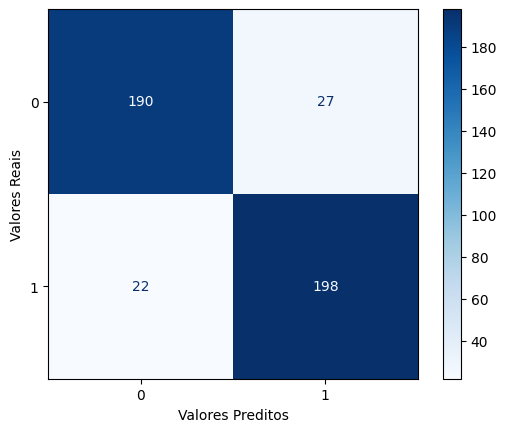

In [ ]:
cm = confusion_matrix(y_test, y_pred)
matrix = ConfusionMatrixDisplay(cm)
matrix.plot(cmap=plt.cm.Blues)
plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.show()

# Utilizando o GridSearchCV

In [ ]:
param_grid ={
    'classifier__C':[0.1, 1, 10, 100],
    'classifier__kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'classifier__gamma': ['auto', 'scale', 0.1, 1]
}

grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    scoring='accuracy',
    cv= 5,
    verbose= 2,
    n_jobs= -1
)

grid_search.fit(X_train, y_train)

best_param = grid_search.best_params_
best_score = grid_search.best_score_

print(f'Melhores parâmetros: {best_param}')
print(f'Melhor Acurácia Média (Validação Cruzada): {best_score * 100:.2f}%')

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Melhores parâmetros: {'classifier__C': 1, 'classifier__gamma': 0.1, 'classifier__kernel': 'poly'}
Melhor Acurácia Média (Validação Cruzada): 94.15%


In [ ]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
acuracia_tuned = accuracy_score(y_test, y_pred_tuned)
print(f'Acurácia do modelo do conjunto de teste: {acuracia_tuned * 100:.2f}%')

Acurácia do modelo do conjunto de teste: 94.28%


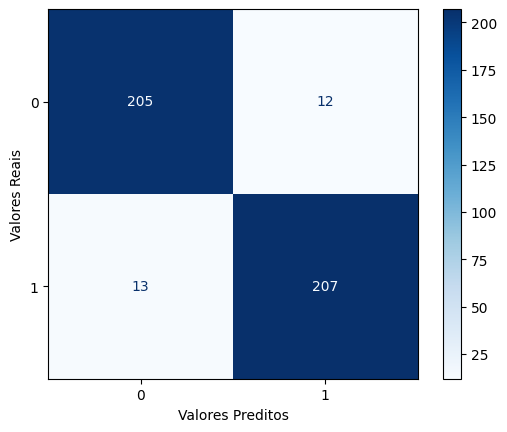

In [ ]:
cm = confusion_matrix(y_test, y_pred_tuned)
matrix = ConfusionMatrixDisplay(cm)
matrix.plot(cmap=plt.cm.Blues)
plt.xlabel('Valores Preditos')
plt.ylabel('Valores Reais')
plt.show()